# Fase 1 — Preparación y procesamiento de datos

### Prototipo de sistema para la detección de phishing en correos electrónicos usando modelos de lenguaje grandes y servidores MCP

**Universidad del Valle de Guatemala — Facultad de Ingeniería**
Ingeniería en Ciencias de la Computación y Tecnologías de la Información

---

## Alcance de este cuaderno

Este cuaderno documenta y ejecuta las actividades **A1.1 (Adquisición y exploración inicial de datasets)** y **A1.2 (Limpieza, normalización y deduplicación del corpus)**, correspondientes a la Fase 1 del proyecto. El objetivo de la Fase 1, según el protocolo aprobado, consiste en procesar los datasets seleccionados para obtener la información necesaria que servirá como insumo para los servidores MCP, proveyendo una base de datos estructurada para analizar patrones semánticos y señales de phishing.

El cuaderno abarca exclusivamente las etapas previas a la ingeniería de características. Comprende la adquisición del corpus, su exploración, la extracción de metadatos y señales, la limpieza, la normalización y la deduplicación del corpus. La ingeniería de características y la construcción de los servidores MCP se abordan en fases posteriores.

## Corpus utilizado

El corpus base corresponde al conjunto de datos publicado por Al-Subaiey et al. (2024), que integra seis fuentes ampliamente utilizadas en la literatura de detección de phishing (Enron, CEAS 2008, Nazario, Ling-Spam, SpamAssassin y Nigerian Fraud), para un total aproximado de 82,500 correos electrónicos.

> **Referencia del conjunto de datos**
> Al-Subaiey, A., Al-Thani, M., Alam, N. A., Antora, K. F., Khandakar, A., & Zaman, S. A. U. (2024). Novel interpretable and robust web-based AI platform for phishing email detection. *Computers & Electrical Engineering, 120*(Part A), Article 109625. https://doi.org/10.1016/j.compeleceng.2024.109625

## Nota sobre la estructura del corpus

El paquete de Kaggle de Al-Subaiey et al. (2024) incluye, además de las seis fuentes originales por separado (`Enron.csv`, `CEAS_08.csv`, `Ling.csv`, `Nazario.csv`, `Nigerian_Fraud.csv`, `SpamAssasin.csv`), un archivo ya consolidado (`phishing_email.csv`) con un único campo de texto plano por correo.

Una verificación inicial mostró que ese archivo consolidado **no es utilizable para la extracción de metadatos**: su texto ya viene sin signos de puntuación (sin `://`, sin `.`, sin `@`), por lo que URLs y direcciones de correo aparecen concatenadas como cadenas alfanuméricas continuas (p. ej. `httpwwwcnncomvideo...`) en lugar de patrones reconocibles. Esto provoca que cualquier extracción por expresión regular reporte cero URLs y cero correos en todo el corpus, ocultando señales que sí están presentes en el texto original.

Por ello, este cuaderno construye el corpus **a partir de las seis fuentes originales por separado**, combinando los campos `subject` y `body` de cada una en un solo campo `text_combined` (igual que hace el archivo consolidado, pero sin la limpieza previa que destruye la puntuación).

Adicionalmente, **cuatro de las seis fuentes** (CEAS 2008, Nazario, Nigerian Fraud y SpamAssassin) incluyen `sender` y `receiver` como columnas separadas y ya limpias — no es necesario reconstruirlas a partir del texto libre. Estas se conservan explícitamente como `remitente` y `destinatario`, y del remitente se deriva además `remitente_dominio`: el dominio de la dirección de correo que envió el mensaje, una señal más confiable que cualquier dirección hallada de forma incidental dentro del cuerpo (útil, en particular, para la Fase 5 de verificación de reputación de dominios). Las otras dos fuentes (Enron y Ling-Spam) no incluyen esta metadata en su CSV original, por lo que estos campos quedan vacíos (`NaN`) para esos registros — se documenta su cobertura en el análisis exploratorio.

Para el resto del contenido, al no existir una estructura de encabezado homogénea entre las seis fuentes dentro del cuerpo del mensaje, la estrategia de preparación no intenta reconstruirlo a partir del texto libre, sino que extrae directamente los elementos verificables (URL y direcciones de correo mencionadas en el cuerpo) y un conjunto de señales léxicas de ingeniería social relevantes para las fases posteriores del proyecto.

---
## 0. Configuración del entorno

Se definen las dependencias, las rutas del proyecto y una semilla global de aleatoriedad. La semilla se fija en `42` para garantizar la reproducibilidad de todos los procesos estocásticos, en consistencia con el valor empleado por Al-Subaiey et al. (2024).

In [1]:
# Dependencias del cuaderno. Ejecutar una sola vez por entorno.
%pip install -q kagglehub pandas numpy langdetect matplotlib seaborn wordcloud

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\50250\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
# Librerías estándar y de terceros
import os
import re
import html
import hashlib
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Semilla global de reproducibilidad
SEED = 42
np.random.seed(SEED)

# Estética de las gráficas
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"

# Paleta consistente para las clases en todo el cuaderno
COLOR_HAM = "#4C72B0"     # legítimo
COLOR_PHISH = "#C44E52"   # phishing/spam
PALETA_CLASE = {0: COLOR_HAM, 1: COLOR_PHISH}

pd.set_option("display.max_colwidth", 120)
print("Entorno configurado. Semilla global =", SEED)

Entorno configurado. Semilla global = 42


In [3]:
# --- Rutas del proyecto ---
# El cuaderno se ejecuta desde 'notebooks/'; la carpeta 'data/' es hermana.
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = BASE_DIR / "data"          # corpus de construcción (CSV)
FIG_DIR  = BASE_DIR / "figures"       # gráficas exportadas
REP_DIR  = BASE_DIR / "reports"       # reporte de calidad

for d in (DATA_DIR, FIG_DIR, REP_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("Directorio base:", BASE_DIR)
print("Datos ->", DATA_DIR)

Directorio base: C:\Users\50250\Desktop\Sofía Mishell Velásquez UVG\Quinto año\Segundo Semestre\Tesis\Trabajo-de-Graduacion
Datos -> C:\Users\50250\Desktop\Sofía Mishell Velásquez UVG\Quinto año\Segundo Semestre\Tesis\Trabajo-de-Graduacion\data


---
# A1.1 — Adquisición y exploración inicial de datasets

Esta actividad obtiene el corpus, verifica su integridad y realiza una exploración inicial de su estructura, dimensiones y distribución de clases.

## A1.1.1 Descarga del corpus

El corpus se obtiene con `kagglehub`, que gestiona la descarga versionada desde Kaggle, asegurando la trazabilidad de la versión utilizada. El paquete descargado incluye tanto el archivo consolidado como las seis fuentes originales por separado; este cuaderno trabaja con las seis fuentes separadas, por las razones expuestas en la nota anterior.

In [4]:
import kagglehub

# Descarga (o recuperación desde caché) de la última versión del corpus.
path = kagglehub.dataset_download("naserabdullahalam/phishing-email-dataset")
print("Ruta de los archivos del dataset:", path)

Ruta de los archivos del dataset: C:\Users\50250\.cache\kagglehub\datasets\naserabdullahalam\phishing-email-dataset\versions\1


In [5]:
# Inspección de los archivos disponibles en el paquete descargado.
for f in sorted(os.listdir(path)):
    tam = os.path.getsize(os.path.join(path, f)) / 1e6
    print(f"{f:35s} {tam:8.2f} MB")

CEAS_08.csv                            67.90 MB
Enron.csv                              45.56 MB
Ling.csv                                9.34 MB
Nazario.csv                             7.81 MB
Nigerian_Fraud.csv                      9.19 MB
SpamAssasin.csv                        14.88 MB
phishing_email.csv                    106.60 MB


Este trabajo emplea las **seis fuentes originales** que integran el corpus de Al-Subaiey et al. (2024) — Enron, CEAS 2008, Ling-Spam, Nazario, Nigerian Fraud y SpamAssassin —, cada una con sus campos `subject` y `body` intactos, en lugar del archivo consolidado `phishing_email.csv`.

In [6]:
# Fuentes originales del corpus (os.path.join para compatibilidad multiplataforma).
FUENTES = ["Enron.csv", "CEAS_08.csv", "Ling.csv", "Nazario.csv", "Nigerian_Fraud.csv", "SpamAssasin.csv"]
RUTAS_FUENTES = [os.path.join(path, nombre) for nombre in FUENTES]

for ruta in RUTAS_FUENTES:
    print("Fuente:", os.path.basename(ruta))

Fuente: Enron.csv
Fuente: CEAS_08.csv
Fuente: Ling.csv
Fuente: Nazario.csv
Fuente: Nigerian_Fraud.csv
Fuente: SpamAssasin.csv


## A1.1.2 Carga y verificación de integridad

Se carga cada fuente con codificación explícita `UTF-8`, práctica de reproducibilidad que evita inconsistencias en la lectura de caracteres especiales. Se combinan los campos `subject` y `body` de cada fuente en un solo campo `text_combined` y se concatenan las seis fuentes en un único corpus (`df_raw`), conservando únicamente `text_combined` y `label`.

In [7]:
# Cuatro de las seis fuentes incluyen 'sender'/'receiver' como columnas separadas y
# ya limpias (Enron y Ling no las traen); se conservan con nombre en español.
# Los NaN indican fuentes que no incluyen esta metadata, no valores faltantes por error.
partes = []
for ruta in RUTAS_FUENTES:
    d = pd.read_csv(ruta, encoding="utf-8")
    subject = d["subject"].fillna("") if "subject" in d.columns else ""
    body = d["body"].fillna("")
    d["text_combined"] = (subject.astype(str) + " " + body.astype(str)).str.strip()
    d["remitente"] = d["sender"] if "sender" in d.columns else np.nan
    d["destinatario"] = d["receiver"] if "receiver" in d.columns else np.nan
    partes.append(d[["text_combined", "label", "remitente", "destinatario"]])

df_raw = pd.concat(partes, ignore_index=True)
print("Corpus cargado a partir de las 6 fuentes originales, codificación UTF-8.")
print(f"Dimensiones: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas")
print(f"Registros con remitente disponible: {df_raw['remitente'].notna().sum():,} "
      f"({df_raw['remitente'].notna().mean()*100:.1f}%)")

Corpus cargado a partir de las 6 fuentes originales, codificación UTF-8.
Dimensiones: 82,486 filas x 4 columnas
Registros con remitente disponible: 49,529 (60.0%)


In [8]:
df_raw.head(3)

,text_combined,label,remitente,destinatario
0,"hpl nom for may 25 , 2001 ( see attached file : hplno 525 . xls )\r\n- hplno 525 . xls",0,NaN,NaN
1,re : nom / actual vols for 24 th - - - - - - - - - - - - - - - - - - - - - - forwarded by sabrae zajac / hou / ect o...,0,NaN,NaN
2,"enron actuals for march 30 - april 1 , 201 estimated actuals\r\nmarch 30 , 2001\r\nno flow\r\nmarch 31 , 2001\r\nno ...",0,NaN,NaN


In [9]:
# Nombres de columna y tipos de dato.
# text_combined : texto del correo (contenido fusionado, sin marcadores de encabezado)
# label         : 1 = phishing/spam, 0 = legítimo/ham
print("Columnas:", list(df_raw.columns))
print()
df_raw.info()

Columnas: ['text_combined', 'label', 'remitente', 'destinatario']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82486 entries, 0 to 82485
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   text_combined  82486 non-null  object
 1   label          82486 non-null  int64 
 2   remitente      49529 non-null  object
 3   destinatario   47768 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.5+ MB


In [10]:
# Valores nulos y filas exactamente duplicadas en el corpus original.
print("Valores nulos por columna:")
print(df_raw.isna().sum())
print(f"\nFilas exactamente duplicadas: {df_raw.duplicated().sum():,}")

Valores nulos por columna:
text_combined        0
label                0
remitente        32957
destinatario     34718
dtype: int64



Filas exactamente duplicadas: 26


## A1.1.3 Distribución de clases

Se analiza la distribución de la variable objetivo (`label`) para caracterizar el balance del corpus, factor determinante para la interpretación de métricas en fases posteriores.

In [11]:
conteo = df_raw["label"].value_counts().sort_index()
proporcion = df_raw["label"].value_counts(normalize=True).sort_index()

resumen_clases = pd.DataFrame({
    "clase": ["Legítimo (ham)", "Phishing/Spam"],
    "etiqueta": conteo.index,
    "cantidad": conteo.values,
    "proporcion_%": (proporcion.values * 100).round(2),
})
resumen_clases

,clase,etiqueta,cantidad,proporcion_%
0,Legítimo (ham),0,39595,48.0
1,Phishing/Spam,1,42891,52.0


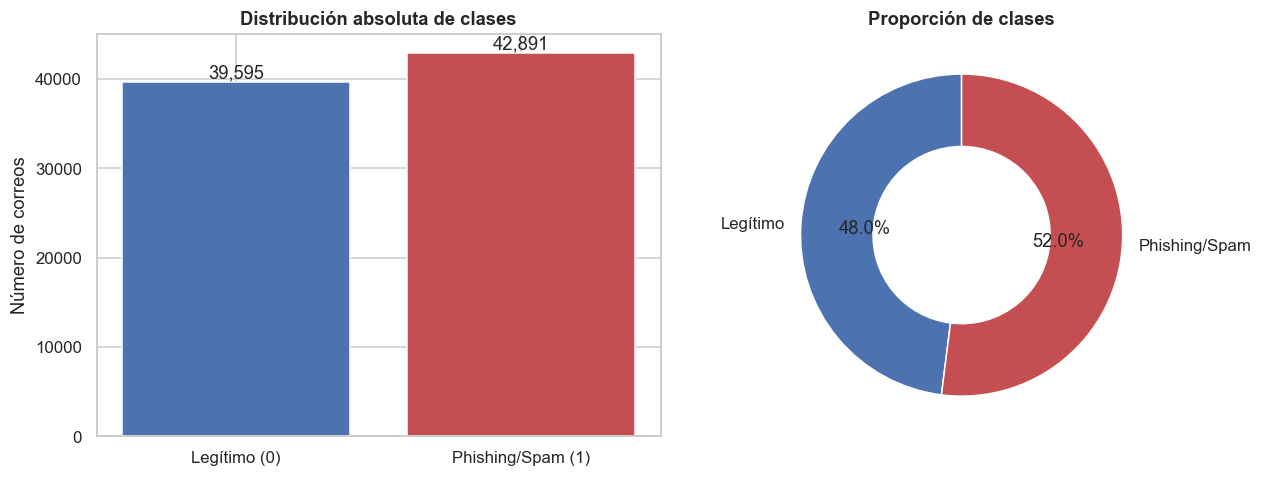

In [12]:
# Gráfica 1: distribución de clases (barras + proporción en anillo).
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Barras absolutas
barras = axes[0].bar(["Legítimo (0)", "Phishing/Spam (1)"], conteo.values,
                     color=[COLOR_HAM, COLOR_PHISH])
axes[0].set_ylabel("Número de correos")
axes[0].set_title("Distribución absoluta de clases")
for b, v in zip(barras, conteo.values):
    axes[0].text(b.get_x()+b.get_width()/2, v, f"{v:,}", ha="center", va="bottom")

# Anillo de proporción
axes[1].pie(conteo.values, labels=["Legítimo", "Phishing/Spam"],
            colors=[COLOR_HAM, COLOR_PHISH], autopct="%1.1f%%",
            startangle=90, wedgeprops=dict(width=0.45))
axes[1].set_title("Proporción de clases")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_distribucion_clases.png", bbox_inches="tight")
plt.show()

El corpus presenta un balance relativamente equilibrado. Este equilibrio reduce el riesgo de sesgo hacia la clase mayoritaria y favorece una evaluación representativa del desempeño del sistema.

## A1.1.4 Caracterización preliminar del texto

Se caracteriza la longitud de los correos y la presencia de elementos que requerirán tratamiento (etiquetas HTML, URL, direcciones de correo). Esta caracterización orienta las decisiones de limpieza.

In [13]:
# Longitud en caracteres y en palabras sobre el texto crudo.
# Se guardan como variables locales (no como columnas de df_raw) para no alterar
# el número de columnas del corpus original, que se reporta más adelante.
texto_raw = df_raw["text_combined"].fillna("").astype(str)
len_chars_raw = texto_raw.str.len()
len_words_raw = texto_raw.str.split().apply(len)

print("Estadísticos de longitud (caracteres) por correo:")
len_chars_raw.describe().round(1)

Estadísticos de longitud (caracteres) por correo:


count      82486.0
mean        1795.8
std        16937.9
min            3.0
25%          338.0
50%          775.0
75%         1953.0
max      4599694.0
Name: text_combined, dtype: float64

In [14]:
# Presencia de elementos estructurales (conteo indicativo que justifica la limpieza).
indicadores = {
    "Etiquetas HTML":            texto_raw.str.contains(r"<[^>]+>", regex=True).sum(),
    "URL (http/https/www)":      texto_raw.str.contains(r"(?:https?://|www\.)", regex=True).sum(),
    "Dirección de correo":       texto_raw.str.contains(r"[\w.\-]+@[\w.\-]+\.\w+", regex=True).sum(),
    "Entidades HTML (&..;)":     texto_raw.str.contains(r"&[a-z]+;", regex=True).sum(),
}
resumen_ind = pd.DataFrame({
    "elemento": list(indicadores.keys()),
    "correos": list(indicadores.values()),
    "porcentaje_%": [round(v/len(df_raw)*100, 2) for v in indicadores.values()],
})
resumen_ind

,elemento,correos,porcentaje_%
0,Etiquetas HTML,4812,5.83
1,URL (http/https/www),32784,39.74
2,Dirección de correo,18205,22.07
3,Entidades HTML (&..;),51,0.06


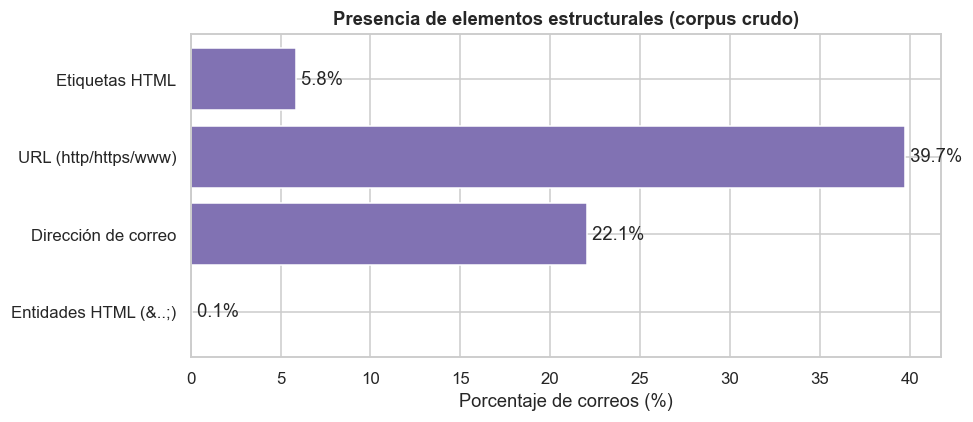

In [15]:
# Gráfica 2: presencia de elementos estructurales en el corpus crudo.
fig, ax = plt.subplots(figsize=(9, 4))
barras = ax.barh(resumen_ind["elemento"], resumen_ind["porcentaje_%"], color="#8172B3")
ax.set_xlabel("Porcentaje de correos (%)")
ax.set_title("Presencia de elementos estructurales (corpus crudo)")
ax.invert_yaxis()
for b, v in zip(barras, resumen_ind["porcentaje_%"]):
    ax.text(v, b.get_y()+b.get_height()/2, f" {v:.1f}%", va="center")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_elementos_estructurales.png", bbox_inches="tight")
plt.show()

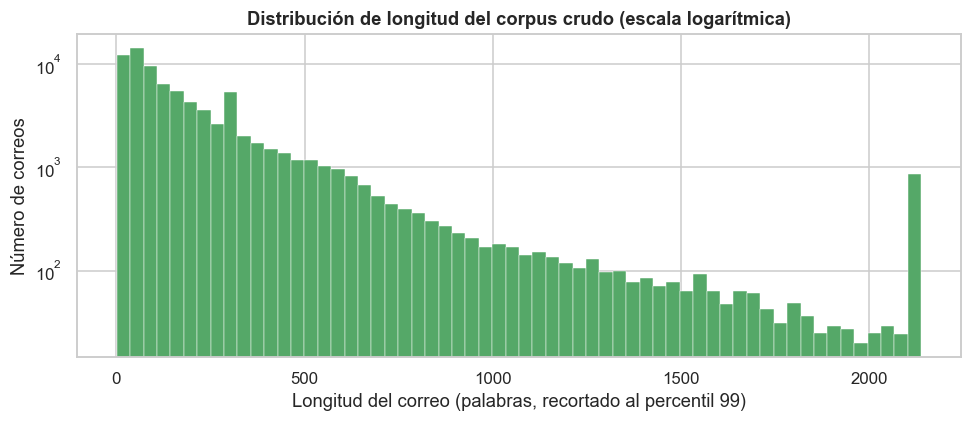

In [16]:
# Gráfica 3: distribución de longitud (palabras) del texto crudo, escala log.
fig, ax = plt.subplots(figsize=(9, 4))
datos = len_words_raw.clip(upper=len_words_raw.quantile(0.99))
ax.hist(datos, bins=60, color="#55A868", edgecolor="white", linewidth=0.3)
ax.set_xlabel("Longitud del correo (palabras, recortado al percentil 99)")
ax.set_ylabel("Número de correos")
ax.set_yscale("log")
ax.set_title("Distribución de longitud del corpus crudo (escala logarítmica)")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_longitud_corpus_crudo.png", bbox_inches="tight")
plt.show()

Los resultados confirman la presencia de HTML, URL y direcciones de correo dentro del texto, y una distribución de longitud con cola larga. Estos hallazgos justifican las operaciones de limpieza y extracción de la actividad A1.2.

---
# A1.2 — Limpieza, normalización y deduplicación del corpus

Esta actividad transforma el corpus crudo en un corpus estructurado, limpio y libre de redundancias. Se compone de: extracción de metadatos y señales, limpieza y normalización del texto, deduplicación, filtrado de registros no válidos y análisis exploratorio del corpus depurado.

## A1.2.1 Extracción de metadatos y señales de ingeniería social

Dado que el texto no contiene marcadores de encabezado, en lugar de reconstruir campos por etiquetas se extraen directamente del texto los elementos que sí son verificables y las señales léxicas relevantes para la detección de phishing:

- **URL y direcciones de correo**: detectadas por patrón, junto con indicadores de riesgo como el uso de URL basadas en direcciones IP.
- **Señales de ingeniería social**: conteos léxicos asociados a tácticas frecuentes en phishing, agrupadas en cuatro categorías: *urgencia*, *incentivo económico*, *solicitud de credenciales* y *llamado a la acción*.
- **Marcadores tipográficos**: proporción de mayúsculas y número de signos de exclamación, empleados habitualmente para transmitir urgencia o presión.

Estas señales cumplen una doble función: enriquecen el análisis exploratorio y anticipan variables que serán formalizadas en la fase de ingeniería de características y evaluadas por el *MCP Pattern Analyzer*.

In [17]:
# --- Patrones de extracción (compilados una sola vez por eficiencia) ---
RE_URL   = re.compile(r"(?:https?://[^\s<>\"']+|www\.[^\s<>\"']+)", re.IGNORECASE)
RE_EMAIL = re.compile(r"[\w.\-]+@[\w.\-]+\.\w+")
RE_IPURL = re.compile(r"https?://\d{1,3}(?:\.\d{1,3}){3}")  # URL con IP (señal de riesgo)

# Léxicos de ingeniería social (en inglés, idioma predominante del corpus).
LEXICOS = {
    "sig_urgencia":     r"\b(urgent|immediately|now|asap|expire[sd]?|suspend(?:ed)?|deadline|verify now|within \d+ ?hours?)\b",
    "sig_dinero":       r"\b(million|usd|prize|won|lottery|reward|inheritance|fund[s]?|wire transfer|cash|payment)\b",
    "sig_credenciales": r"\b(password|account|verify|log[- ]?in|confirm|security|ssn|bank|credential[s]?)\b",
    "sig_accion":       r"\b(click|download|open the|reply|call us|visit|follow the link|update your)\b",
}
LEXICOS_C = {k: re.compile(v, re.IGNORECASE) for k, v in LEXICOS.items()}

print("Patrones compilados:", len(LEXICOS_C) + 3, "extractores")

Patrones compilados: 7 extractores


In [18]:
def extraer_senales(texto: str) -> dict:
    '''
    Extrae metadatos verificables y señales de ingeniería social de un correo.

    Parámetros
    ----------
    texto : str
        Contenido del correo (campo 'text_combined').

    Retorna
    -------
    dict
        URLs, dominios, conteos de señales léxicas y marcadores tipográficos.
    '''
    if not isinstance(texto, str):
        texto = ""

    # --- URLs y correos ---
    urls = list(dict.fromkeys(RE_URL.findall(texto)))
    emails = list(dict.fromkeys(RE_EMAIL.findall(texto)))

    # Dominios de las direcciones de correo halladas (útil para la Fase 5)
    dominios = list(dict.fromkeys(
        e.split("@")[-1].lower() for e in emails if "@" in e))

    resultado = {
        "n_urls": len(urls),
        "n_emails": len(emails),
        "tiene_url_ip": bool(RE_IPURL.search(texto)),  # URL con IP: señal de riesgo
        "urls": urls,
        "dominios_email": dominios,
    }

    # --- Señales de ingeniería social (conteo por categoría) ---
    for nombre, patron in LEXICOS_C.items():
        resultado[nombre] = len(patron.findall(texto))

    # --- Marcadores tipográficos ---
    n = max(len(texto), 1)
    resultado["ratio_mayusculas"] = round(sum(1 for ch in texto if ch.isupper()) / n, 4)
    resultado["n_exclamaciones"] = texto.count("!")

    return resultado

# Verificación sobre un ejemplo del corpus
extraer_senales(df_raw["text_combined"].iloc[0])

{'n_urls': 0,
 'n_emails': 0,
 'tiene_url_ip': False,
 'urls': [],
 'dominios_email': [],
 'sig_urgencia': 0,
 'sig_dinero': 0,
 'sig_credenciales': 0,
 'sig_accion': 0,
 'ratio_mayusculas': 0.0,
 'n_exclamaciones': 0}

In [19]:
# Aplicación de la extracción a todo el corpus.
senales = df_raw["text_combined"].apply(extraer_senales)
df = pd.DataFrame(list(senales))
df.insert(0, "text_combined", df_raw["text_combined"].values)
df["label"] = df_raw["label"].values
df["remitente"] = df_raw["remitente"].values
df["destinatario"] = df_raw["destinatario"].values

# Dominio del remitente (cuando la fuente lo incluye como campo propio): señal más
# confiable que cualquier dirección de correo hallada de forma incidental en el cuerpo.
df["remitente_dominio"] = df["remitente"].apply(
    lambda r: (RE_EMAIL.search(r).group(0).split("@")[-1].lower()
               if isinstance(r, str) and RE_EMAIL.search(r) else np.nan))

print("Corpus con señales extraídas:", df.shape)
print(f"Dominio de remitente identificado: {df['remitente_dominio'].notna().sum():,} "
      f"({df['remitente_dominio'].notna().mean()*100:.1f}%)")
df.head(3)

Corpus con señales extraídas: (82486, 16)
Dominio de remitente identificado: 48,506 (58.8%)


,text_combined,n_urls,n_emails,tiene_url_ip,urls,dominios_email,sig_urgencia,sig_dinero,sig_credenciales,sig_accion,ratio_mayusculas,n_exclamaciones,label,remitente,destinatario,remitente_dominio
0,"hpl nom for may 25 , 2001 ( see attached file : hplno 525 . xls )\r\n- hplno 525 . xls",0,0,False,[],[],0,0,0,0,0.0,0,0,NaN,NaN,NaN
1,re : nom / actual vols for 24 th - - - - - - - - - - - - - - - - - - - - - - forwarded by sabrae zajac / hou / ect o...,0,0,False,[],[],0,0,0,0,0.0,0,0,NaN,NaN,NaN
2,"enron actuals for march 30 - april 1 , 201 estimated actuals\r\nmarch 30 , 2001\r\nno flow\r\nmarch 31 , 2001\r\nno ...",0,0,False,[],[],0,0,0,0,0.0,0,0,NaN,NaN,NaN


## A1.2.2 Limpieza y normalización del texto

Se depura el contenido textual para eliminar ruido que no aporta valor semántico:

1. Decodificación de entidades HTML.
2. Eliminación de etiquetas HTML residuales.
3. Normalización de URL y direcciones de correo a los marcadores `URL` y `EMAIL`.
4. Colapso de espacios en blanco múltiples.

La sustitución de URL y correos por marcadores preserva la señal de su presencia sin arrastrar cadenas específicas que introducirían dispersión léxica; las URL originales ya se conservaron en el campo `urls`. No se aplican operaciones agresivas (eliminación de *stopwords*, lematización, conversión total a minúsculas), ya que el análisis semántico del proyecto requiere preservar el texto en su forma natural, portadora de señales de ingeniería social.

In [20]:
def limpiar_texto(texto: str) -> str:
    '''Limpieza y normalización ligera del texto de un correo.'''
    if not isinstance(texto, str):
        return ""
    texto = html.unescape(texto)                 # entidades HTML -> caracteres
    texto = re.sub(r"<[^>]+>", " ", texto)       # elimina etiquetas HTML
    texto = RE_URL.sub(" URL ", texto)           # URL -> marcador
    texto = RE_EMAIL.sub(" EMAIL ", texto)       # correo -> marcador
    texto = re.sub(r"\s+", " ", texto).strip()   # colapsa espacios
    return texto

df["text_clean"] = df["text_combined"].apply(limpiar_texto)

# Longitud del texto limpio
df["len_chars"] = df["text_clean"].str.len()
df["len_words"] = df["text_clean"].str.split().apply(len)

df[["text_combined", "text_clean"]].head(3)

,text_combined,text_clean
0,"hpl nom for may 25 , 2001 ( see attached file : hplno 525 . xls )\r\n- hplno 525 . xls","hpl nom for may 25 , 2001 ( see attached file : hplno 525 . xls ) - hplno 525 . xls"
1,re : nom / actual vols for 24 th - - - - - - - - - - - - - - - - - - - - - - forwarded by sabrae zajac / hou / ect o...,re : nom / actual vols for 24 th - - - - - - - - - - - - - - - - - - - - - - forwarded by sabrae zajac / hou / ect o...
2,"enron actuals for march 30 - april 1 , 201 estimated actuals\r\nmarch 30 , 2001\r\nno flow\r\nmarch 31 , 2001\r\nno ...","enron actuals for march 30 - april 1 , 201 estimated actuals march 30 , 2001 no flow march 31 , 2001 no flow april 1..."


In [21]:
df[["len_chars", "len_words"]].describe().round(1)

,len_chars,len_words
count,82486.0,82486.0
mean,1607.3,278.9
std,16272.0,850.9
min,3.0,1.0
25%,321.0,58.0
50%,721.0,136.0
75%,1824.0,302.0
max,4519585.0,127506.0


## A1.2.3 Deduplicación del corpus

La fusión de seis fuentes puede introducir correos duplicados, de forma exacta o con variaciones de formato. Los duplicados sesgan la caracterización del corpus. Se aplican dos criterios:

- **Duplicados exactos**: idéntico texto original.
- **Duplicados normalizados**: idéntico texto tras homogeneizar mayúsculas y espacios, capturado mediante una clave *hash* (MD5) para una comparación eficiente sobre el volumen completo.

In [22]:
def clave_normalizada(texto: str) -> str:
    '''Genera una clave MD5 sobre una versión normalizada del texto (para deduplicar).'''
    base = re.sub(r"\s+", " ", str(texto).lower().strip())
    return hashlib.md5(base.encode("utf-8")).hexdigest()

df["dedup_key"] = df["text_clean"].apply(clave_normalizada)

dup_exactos = int(df["text_combined"].duplicated().sum())
dup_norm = int(df["dedup_key"].duplicated().sum())
print(f"Duplicados exactos (texto original):     {dup_exactos:,}")
print(f"Duplicados normalizados (texto limpio):  {dup_norm:,}")

Duplicados exactos (texto original):     45
Duplicados normalizados (texto limpio):  5,213


In [23]:
# Eliminación de duplicados normalizados, conservando la primera aparición.
n_antes = len(df)
df_dedup = df.drop_duplicates(subset="dedup_key", keep="first").reset_index(drop=True)
n_despues = len(df_dedup)
print(f"Registros antes de deduplicar:   {n_antes:,}")
print(f"Registros después de deduplicar: {n_despues:,}")
print(f"Registros eliminados:            {n_antes - n_despues:,}")

Registros antes de deduplicar:   82,486
Registros después de deduplicar: 77,273
Registros eliminados:            5,213


## A1.2.4 Filtrado de registros no válidos

Se descartan los registros sin contenido analizable: cuerpos vacíos, con menos de un umbral mínimo de palabras, o sin etiqueta. Se adopta un umbral de **tres palabras**, valor configurable que descarta fragmentos triviales sin eliminar mensajes legítimamente breves.

In [24]:
MIN_PALABRAS = 3  # parámetro configurable

mask_vacios = df_dedup["text_clean"].str.strip().eq("")
mask_cortos = df_dedup["len_words"] < MIN_PALABRAS
mask_nulos  = df_dedup["label"].isna()

print(f"Cuerpos vacíos:            {int(mask_vacios.sum()):,}")
print(f"Cuerpos con < {MIN_PALABRAS} palabras:   {int(mask_cortos.sum()):,}")
print(f"Etiqueta ausente:         {int(mask_nulos.sum()):,}")

Cuerpos vacíos:            0
Cuerpos con < 3 palabras:   6
Etiqueta ausente:         0


In [25]:
mask_invalidos = mask_vacios | mask_cortos | mask_nulos
df_clean = df_dedup.loc[~mask_invalidos].reset_index(drop=True)
df_clean["label"] = df_clean["label"].astype(int)

print(f"Registros tras el filtrado: {len(df_clean):,}")
print(f"Registros descartados:      {int(mask_invalidos.sum()):,}")

Registros tras el filtrado: 77,267


Registros descartados:      6


In [26]:
# Verificación del balance de clases tras la limpieza.
balance = df_clean["label"].value_counts(normalize=True).sort_index() * 100
print("Distribución de clases tras la limpieza (%):")
print(f"  Legítimo (0): {balance.get(0,0):.2f}%")
print(f"  Phishing (1): {balance.get(1,0):.2f}%")

Distribución de clases tras la limpieza (%):
  Legítimo (0): 50.73%
  Phishing (1): 49.27%


## A1.2.5 Análisis exploratorio del corpus depurado

Se caracteriza el corpus depurado a través de múltiples dimensiones relevantes para el diseño de los servidores MCP: la longitud por clase, las señales de ingeniería social, la presencia de URL y su relación con la clase, el idioma predominante y los dominios más frecuentes.

### Longitud del cuerpo por clase

Se compara la distribución de longitud entre correos legítimos y de phishing mediante histograma y diagrama de caja.

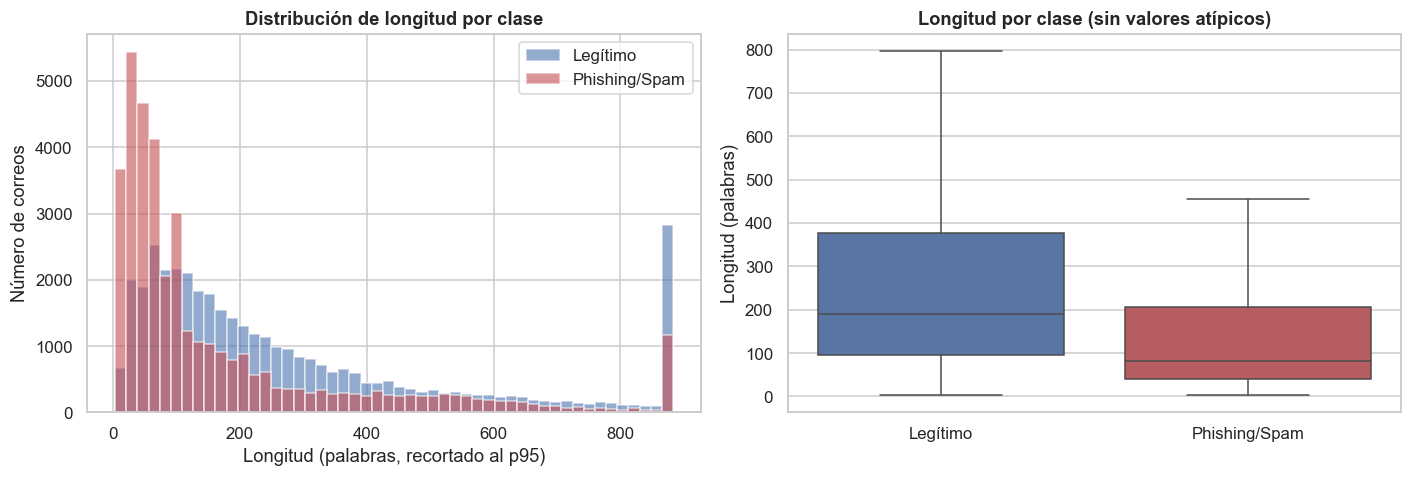

In [27]:
# Gráfica 4: longitud por clase (histograma superpuesto + boxplot).
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Histograma superpuesto (recorte al percentil 95 por legibilidad)
tope = df_clean["len_words"].quantile(0.95)
for etq, nombre, color in [(0,"Legítimo",COLOR_HAM), (1,"Phishing/Spam",COLOR_PHISH)]:
    d = df_clean.loc[df_clean["label"]==etq, "len_words"].clip(upper=tope)
    axes[0].hist(d, bins=50, alpha=0.6, label=nombre, color=color)
axes[0].set_xlabel("Longitud (palabras, recortado al p95)")
axes[0].set_ylabel("Número de correos")
axes[0].set_title("Distribución de longitud por clase")
axes[0].legend()

# Boxplot por clase
df_box = df_clean.copy()
df_box["clase"] = df_box["label"].map({0:"Legítimo",1:"Phishing/Spam"})
sns.boxplot(data=df_box, x="clase", y="len_words", hue="clase",
            palette=[COLOR_HAM, COLOR_PHISH], legend=False, ax=axes[1], showfliers=False)
axes[1].set_ylabel("Longitud (palabras)")
axes[1].set_xlabel("")
axes[1].set_title("Longitud por clase (sin valores atípicos)")

plt.tight_layout()
plt.savefig(FIG_DIR / "04_longitud_por_clase.png", bbox_inches="tight")
plt.show()

In [28]:
df_clean.groupby("label")["len_words"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,39201.0,362.9,863.5,3.0,95.0,190.0,376.0,45450.0
1,38066.0,202.0,885.4,3.0,40.0,82.0,206.0,127506.0


### Señales de ingeniería social por clase

Se comparan los conteos promedio de las cuatro categorías de señales léxicas entre clases. Diferencias marcadas confirman su valor discriminativo y su pertinencia como insumo del *MCP Pattern Analyzer*.

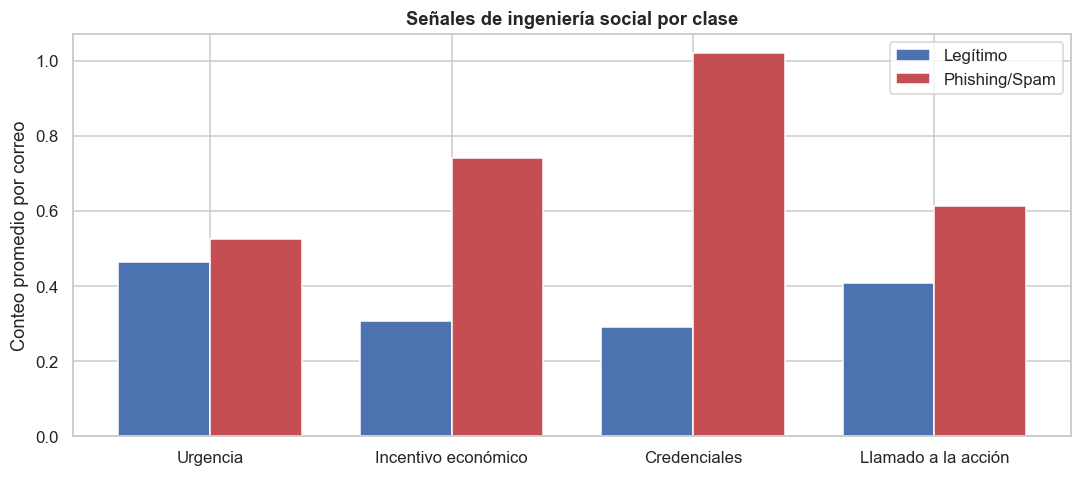

,sig_urgencia,sig_dinero,sig_credenciales,sig_accion
label,,,,
0,0.465,0.308,0.290,0.409
1,0.525,0.740,1.021,0.613


In [29]:
# Gráfica 5: promedio de señales de ingeniería social por clase.
cols_senales = ["sig_urgencia", "sig_dinero", "sig_credenciales", "sig_accion"]
promedios = df_clean.groupby("label")[cols_senales].mean()

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(cols_senales))
ancho = 0.38
ax.bar(x - ancho/2, promedios.loc[0], ancho, label="Legítimo", color=COLOR_HAM)
ax.bar(x + ancho/2, promedios.loc[1], ancho, label="Phishing/Spam", color=COLOR_PHISH)
ax.set_xticks(x)
ax.set_xticklabels(["Urgencia", "Incentivo económico", "Credenciales", "Llamado a la acción"])
ax.set_ylabel("Conteo promedio por correo")
ax.set_title("Señales de ingeniería social por clase")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "05_senales_por_clase.png", bbox_inches="tight")
plt.show()

promedios.round(3)

### Presencia de URL y marcadores de riesgo

Se analiza la proporción de correos que contienen al menos una URL y aquellos con URL basadas en direcciones IP, un indicador frecuente de phishing.

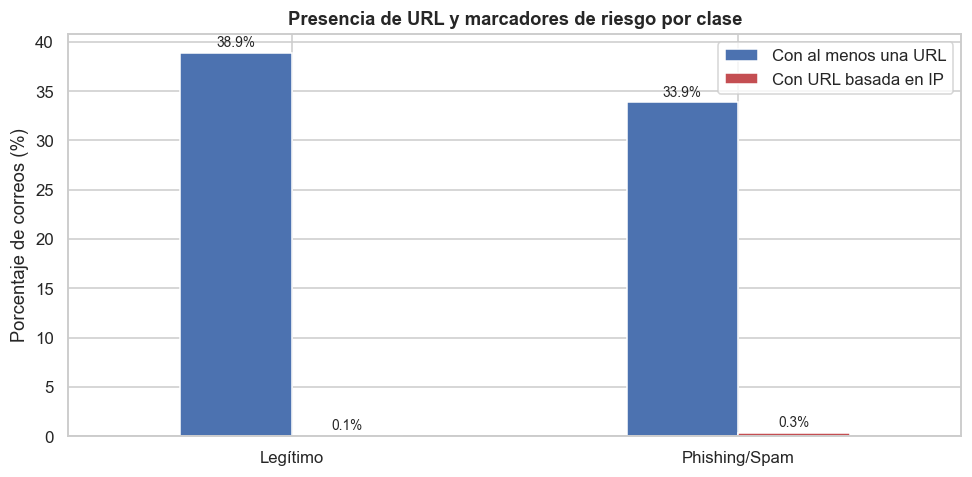

,Con al menos una URL,Con URL basada en IP
Legítimo,38.87,0.06
Phishing/Spam,33.86,0.34


In [30]:
# Gráfica 6: presencia de URL y URL con IP por clase.
resumen_url = pd.DataFrame({
    "Con al menos una URL": df_clean.groupby("label").apply(lambda g: (g["n_urls"]>0).mean()*100),
    "Con URL basada en IP": df_clean.groupby("label")["tiene_url_ip"].mean()*100,
})
resumen_url.index = ["Legítimo", "Phishing/Spam"]

fig, ax = plt.subplots(figsize=(9, 4.5))
resumen_url.plot(kind="bar", ax=ax, color=["#4C72B0", "#C44E52"], rot=0)
ax.set_ylabel("Porcentaje de correos (%)")
ax.set_title("Presencia de URL y marcadores de riesgo por clase")
ax.legend(title="")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.1f%%", padding=2, fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "06_url_riesgo_por_clase.png", bbox_inches="tight")
plt.show()

resumen_url.round(2)

### Marcadores tipográficos

Se comparan la proporción de mayúsculas y el número de signos de exclamación, recursos habituales para transmitir urgencia o presión en los correos fraudulentos.

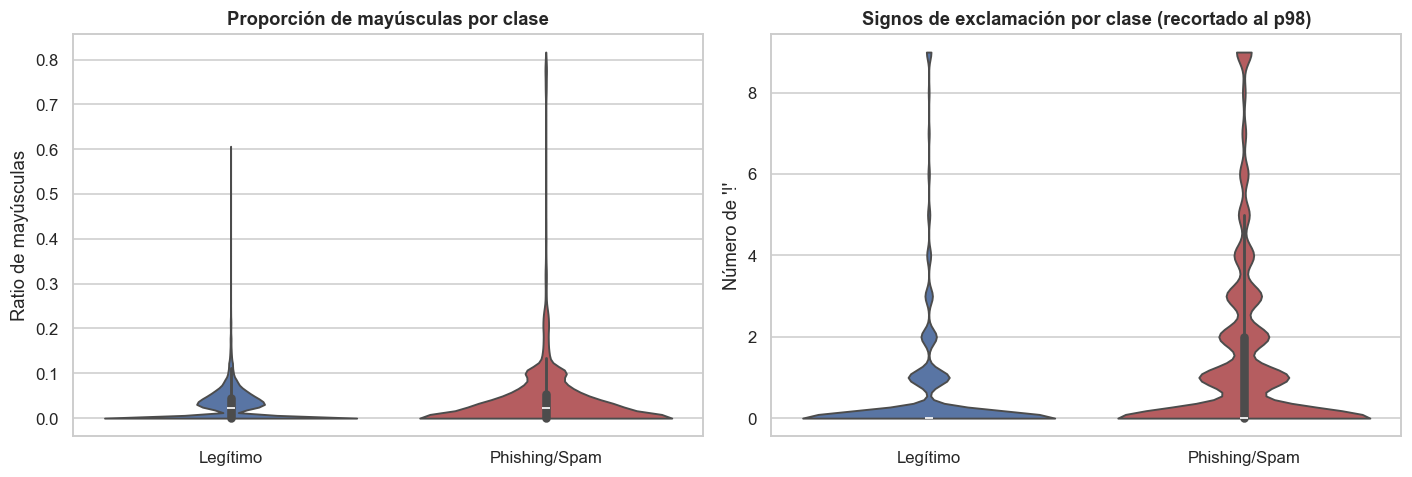

In [31]:
# Gráfica 7: marcadores tipográficos por clase (violin plots).
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
df_box = df_clean.copy()
df_box["clase"] = df_box["label"].map({0:"Legítimo",1:"Phishing/Spam"})

sns.violinplot(data=df_box, x="clase", y="ratio_mayusculas", hue="clase",
               palette=[COLOR_HAM,COLOR_PHISH], legend=False, ax=axes[0], cut=0)
axes[0].set_title("Proporción de mayúsculas por clase")
axes[0].set_xlabel(""); axes[0].set_ylabel("Ratio de mayúsculas")

exc = df_box.copy()
exc["n_exclamaciones"] = exc["n_exclamaciones"].clip(upper=exc["n_exclamaciones"].quantile(0.98))
sns.violinplot(data=exc, x="clase", y="n_exclamaciones", hue="clase",
               palette=[COLOR_HAM,COLOR_PHISH], legend=False, ax=axes[1], cut=0)
axes[1].set_title("Signos de exclamación por clase (recortado al p98)")
axes[1].set_xlabel(""); axes[1].set_ylabel("Número de '!'")

plt.tight_layout()
plt.savefig(FIG_DIR / "07_marcadores_tipograficos.png", bbox_inches="tight")
plt.show()

### Identificación de idioma

Se cuantifica la composición idiomática del corpus mediante identificación automática sobre una muestra representativa. El idioma condiciona el análisis semántico y la interpretación de las señales de ingeniería social, y el protocolo delimita el alcance al contenido textual del correo.

In [32]:
from langdetect import detect, DetectorFactory
DetectorFactory.seed = SEED  # reproducibilidad del detector

def detectar_idioma(texto: str) -> str:
    '''Detecta el idioma de un texto; retorna "unknown" si no es posible.'''
    try:
        return detect(texto) if isinstance(texto,str) and len(texto.strip())>20 else "unknown"
    except Exception:
        return "unknown"

N_MUESTRA = 3000
muestra = df_clean["text_clean"].sample(n=min(N_MUESTRA, len(df_clean)), random_state=SEED)
idiomas = muestra.apply(detectar_idioma)
dist_idiomas = (idiomas.value_counts(normalize=True) * 100).head(8)
print(f"Composición idiomática estimada (muestra de {len(muestra):,} correos):")
dist_idiomas.round(2)

Composición idiomática estimada (muestra de 3,000 correos):


text_clean
en    98.90
es     0.20
ca     0.13
pl     0.13
de     0.10
cy     0.10
fr     0.10
pt     0.10
Name: proportion, dtype: float64

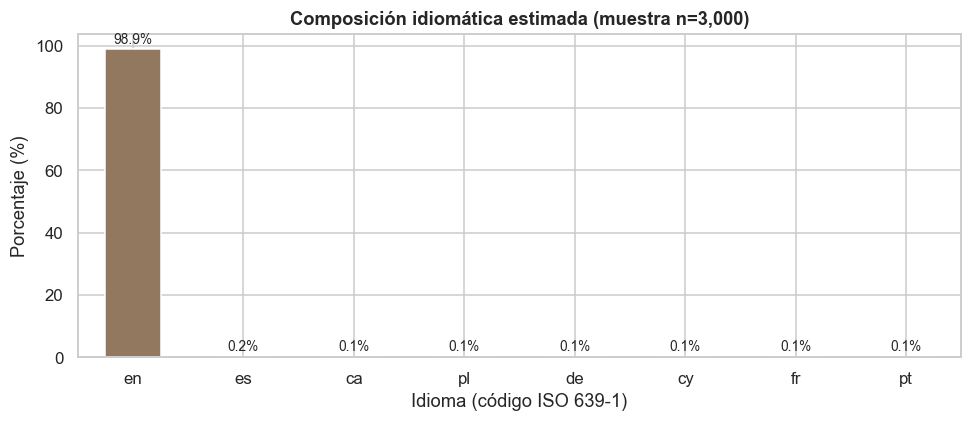

In [33]:
# Gráfica 8: composición idiomática estimada.
fig, ax = plt.subplots(figsize=(9, 4))
dist_idiomas.plot(kind="bar", ax=ax, color="#937860", rot=0)
ax.set_ylabel("Porcentaje (%)")
ax.set_xlabel("Idioma (código ISO 639-1)")
ax.set_title(f"Composición idiomática estimada (muestra n={len(muestra):,})")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2, fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "08_idiomas.png", bbox_inches="tight")
plt.show()

### Correlación entre señales numéricas

Se examina la correlación entre las señales numéricas extraídas y la etiqueta de clase. Este análisis anticipa qué señales podrían aportar mayor valor discriminativo en la fase de ingeniería de características.

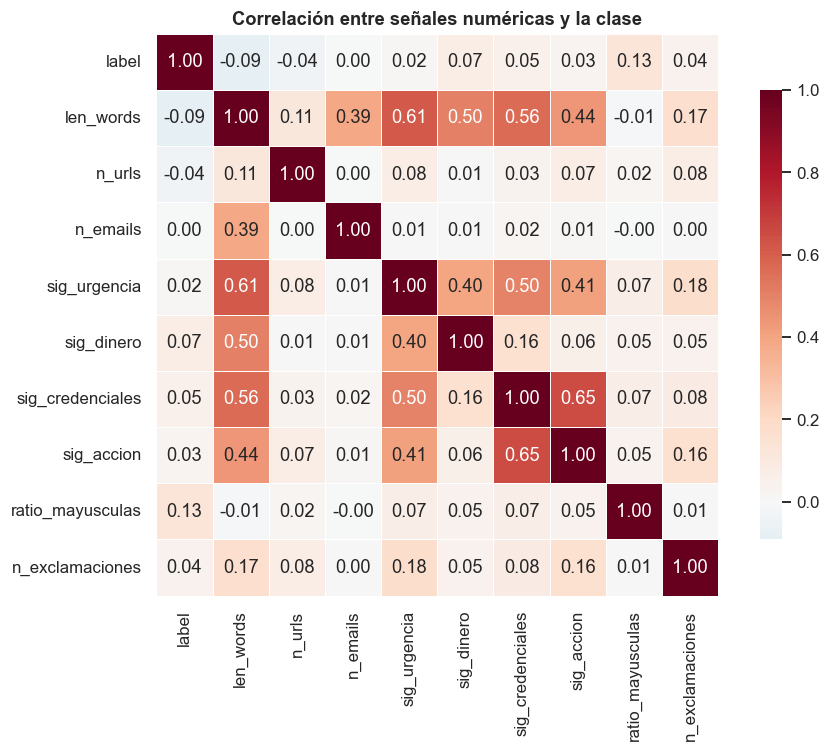

In [34]:
# Gráfica 9: matriz de correlación de señales numéricas con la clase.
cols_num = ["label", "len_words", "n_urls", "n_emails",
            "sig_urgencia", "sig_dinero", "sig_credenciales", "sig_accion",
            "ratio_mayusculas", "n_exclamaciones"]
corr = df_clean[cols_num].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink":0.8}, ax=ax)
ax.set_title("Correlación entre señales numéricas y la clase")
plt.tight_layout()
plt.savefig(FIG_DIR / "09_correlacion_senales.png", bbox_inches="tight")
plt.show()

In [35]:
# Correlación de cada señal con la etiqueta, ordenada por magnitud.
corr_label = corr["label"].drop("label").sort_values(key=abs, ascending=False)
print("Correlación de cada señal con la clase (ordenada por magnitud):")
corr_label.round(3)

Correlación de cada señal con la clase (ordenada por magnitud):


ratio_mayusculas    0.126
len_words          -0.092
sig_dinero          0.074
sig_credenciales    0.053
n_urls             -0.044
n_exclamaciones     0.042
sig_accion          0.031
sig_urgencia        0.019
n_emails            0.001
Name: label, dtype: float64

### Dominios de correo más frecuentes

Se examinan los dominios de correo desde dos fuentes de distinta confiabilidad: los hallados de forma incidental dentro del texto del mensaje (`dominios_email`, cualquier dirección mencionada en el cuerpo) y el dominio del **remitente real** del mensaje (`remitente_dominio`, disponible solo para las cuatro fuentes que incluyen esa metadata). El análisis de dominios es pertinente para la Fase 5 (integración con fuentes técnicas externas), donde serán objeto de verificación mediante servicios de reputación.

Correos con al menos un dominio identificado: 15,158


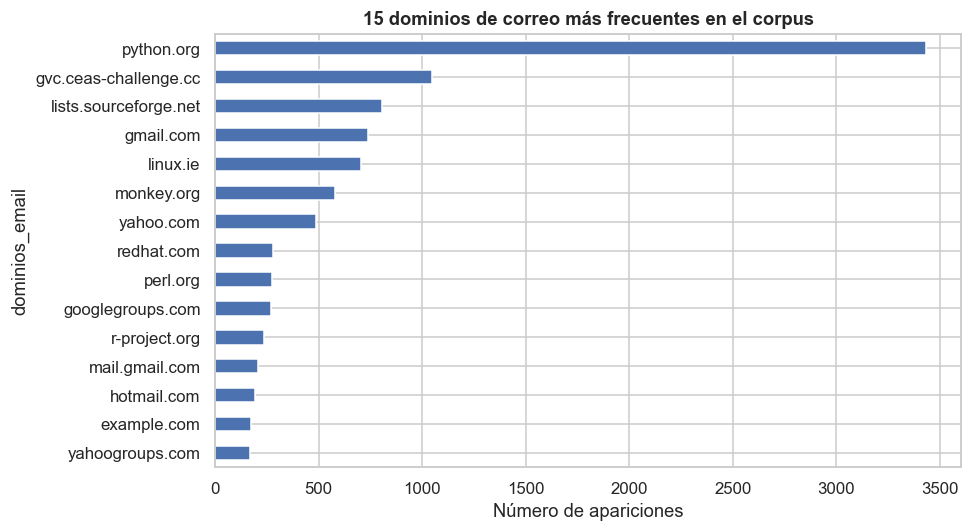

dominios_email
python.org               3433
gvc.ceas-challenge.cc    1048
lists.sourceforge.net     806
gmail.com                 739
linux.ie                  706
monkey.org                579
yahoo.com                 485
redhat.com                278
perl.org                  277
googlegroups.com          270
r-project.org             236
mail.gmail.com            208
hotmail.com               192
example.com               171
yahoogroups.com           169
Name: count, dtype: int64

In [36]:
# Explosión de la lista de dominios para conteo global.
dominios_all = df_clean["dominios_email"].explode().dropna()
dominios_all = dominios_all[dominios_all != ""]
top_dom = dominios_all.value_counts().head(15)

print(f"Correos con al menos un dominio identificado: {(df_clean['dominios_email'].apply(len)>0).sum():,}")

# Gráfica 10: dominios más frecuentes.
if len(top_dom) > 0:
    fig, ax = plt.subplots(figsize=(9, 5))
    top_dom.sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
    ax.set_xlabel("Número de apariciones")
    ax.set_title("15 dominios de correo más frecuentes en el corpus")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "10_dominios_frecuentes.png", bbox_inches="tight")
    plt.show()
top_dom

Correos con dominio de remitente identificado: 43,968 (56.9%)


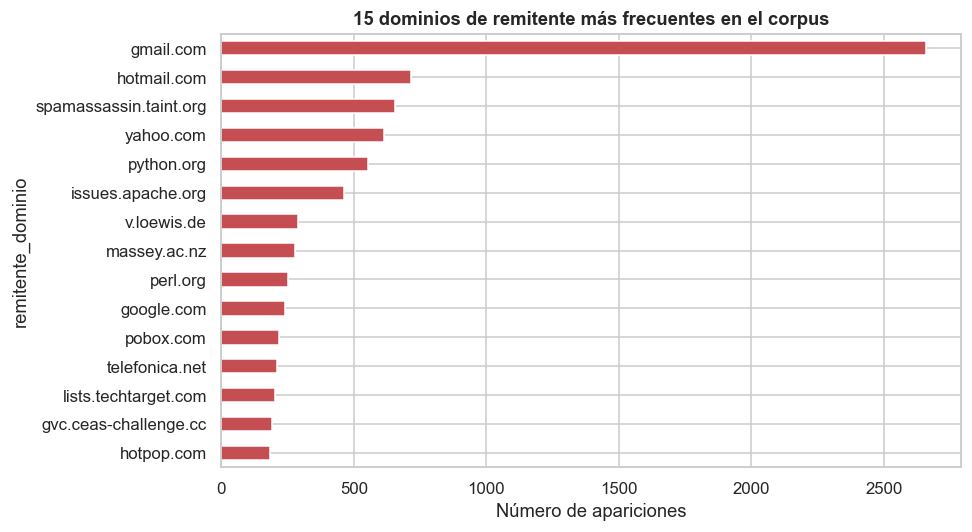

remitente_dominio
gmail.com                 2660
hotmail.com                716
spamassassin.taint.org     655
yahoo.com                  614
python.org                 555
issues.apache.org          462
v.loewis.de                289
massey.ac.nz               279
perl.org                   251
google.com                 240
pobox.com                  217
telefonica.net             209
lists.techtarget.com       201
gvc.ceas-challenge.cc      192
hotpop.com                 185
Name: count, dtype: int64

In [37]:
# Gráfica 11: dominios de remitente más frecuentes (señal confiable, no incidental).
cobertura_remitente = df_clean["remitente_dominio"].notna().mean() * 100
print(f"Correos con dominio de remitente identificado: "
      f"{df_clean['remitente_dominio'].notna().sum():,} ({cobertura_remitente:.1f}%)")

top_dom_remitente = df_clean["remitente_dominio"].dropna().value_counts().head(15)

if len(top_dom_remitente) > 0:
    fig, ax = plt.subplots(figsize=(9, 5))
    top_dom_remitente.sort_values().plot(kind="barh", ax=ax, color="#C44E52")
    ax.set_xlabel("Número de apariciones")
    ax.set_title("15 dominios de remitente más frecuentes en el corpus")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "11_dominios_remitente_frecuentes.png", bbox_inches="tight")
    plt.show()
top_dom_remitente

### Nubes de palabras por clase

Se generan nubes de palabras a partir del texto limpio (`text_clean`) para cada clase, como resumen visual del vocabulario más frecuente. Se excluyen las palabras vacías del idioma inglés (predominante en el corpus, según la sección de identificación de idioma) y los marcadores estructurales `URL`/`EMAIL` introducidos en la limpieza, ya que no aportan contenido léxico.

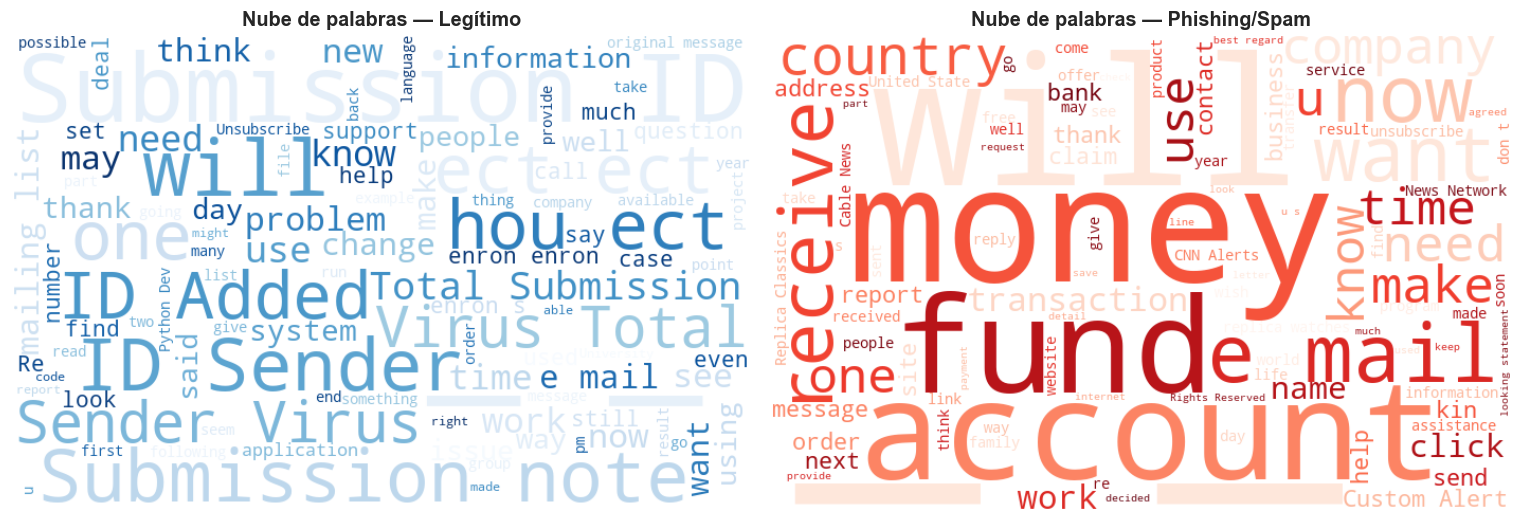

In [38]:
# Gráfica 12: nubes de palabras por clase.
from wordcloud import WordCloud, STOPWORDS

STOPWORDS_EXTRA = STOPWORDS.union({"url", "email", "subject"})

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, etq, nombre, cmap in [(axes[0], 0, "Legítimo", "Blues"),
                               (axes[1], 1, "Phishing/Spam", "Reds")]:
    texto_clase = " ".join(df_clean.loc[df_clean["label"] == etq, "text_clean"])
    nube = WordCloud(width=700, height=450, background_color="white",
                      colormap=cmap, max_words=100, stopwords=STOPWORDS_EXTRA,
                      random_state=SEED).generate(texto_clase)
    ax.imshow(nube, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(f"Nube de palabras — {nombre}", fontsize=13)

plt.tight_layout()
plt.savefig(FIG_DIR / "12_wordcloud_por_clase.png", bbox_inches="tight")
plt.show()

## A1.2.7 Exportación de artefactos

Se consolidan y exportan los artefactos en formato **CSV** (codificación UTF-8), elegido por su portabilidad y facilidad de inspección. Se selecciona un esquema de columnas con los campos relevantes para las fases posteriores. Las listas (URL y dominios) se serializan como cadenas para su almacenamiento en CSV.

In [39]:
# Esquema de columnas del corpus de construcción.
COLUMNAS = [
    "label", "text_clean",
    "len_words", "len_chars",
    "remitente", "destinatario", "remitente_dominio",
    "n_urls", "n_emails", "tiene_url_ip",
    "sig_urgencia", "sig_dinero", "sig_credenciales", "sig_accion",
    "ratio_mayusculas", "n_exclamaciones",
    "urls", "dominios_email", "dedup_key",
]

df_final = df_clean[COLUMNAS].copy()

# Serialización de listas a cadena (para CSV). Se usa '|' como separador interno.
df_final["urls"] = df_final["urls"].apply(lambda x: " | ".join(x) if isinstance(x, list) else "")
df_final["dominios_email"] = df_final["dominios_email"].apply(
    lambda x: " | ".join(x) if isinstance(x, list) else "")

print("Corpus de construcción final:", df_final.shape)
df_final.head(3)


Corpus de construcción final: (77267, 19)


,label,text_clean,len_words,len_chars,remitente,destinatario,remitente_dominio,n_urls,n_emails,tiene_url_ip,sig_urgencia,sig_dinero,sig_credenciales,sig_accion,ratio_mayusculas,n_exclamaciones,urls,dominios_email,dedup_key
0,0,"hpl nom for may 25 , 2001 ( see attached file : hplno 525 . xls ) - hplno 525 . xls",22,83,NaN,NaN,NaN,0,0,False,0,0,0,0,0.0,0,,,f5682447bb01e8e912b5c09aa9b508cc
1,0,re : nom / actual vols for 24 th - - - - - - - - - - - - - - - - - - - - - - forwarded by sabrae zajac / hou / ect o...,435,1607,NaN,NaN,NaN,0,0,False,0,0,0,0,0.0,0,,,f61bdea65810815bff91f0e71662fa50
2,0,"enron actuals for march 30 - april 1 , 201 estimated actuals march 30 , 2001 no flow march 31 , 2001 no flow april 1...",47,207,NaN,NaN,NaN,0,0,False,0,0,0,0,0.0,0,,,8a38001a2f872bf7a8f63238b9d86fe1


In [40]:
# --- Exportación a CSV: corpus de construcción completo ---
ruta_total = DATA_DIR / "corpus_construccion.csv"
df_final.to_csv(ruta_total, index=False, encoding="utf-8")
print("Corpus de construcción exportado:", ruta_total.name, f"({len(df_final):,} filas)")


Corpus de construcción exportado: corpus_construccion.csv (77,267 filas)


## A1.2.8 Reporte de calidad de datos

Se genera un reporte que sintetiza las transformaciones aplicadas y las características del corpus resultante, documentando la trazabilidad del proceso. Se exporta en Markdown para su incorporación a la documentación de la tesis.

In [41]:
reporte = f'''# Reporte de Calidad de Datos — Fase 1

**Proyecto:** Prototipo de detección de phishing con LLM y servidores MCP
**Fecha de generación:** {datetime.now().strftime('%Y-%m-%d %H:%M')}
**Actividades:** A1.1 (Adquisición y exploración) y A1.2 (Limpieza, normalización y deduplicación)

## 1. Corpus de origen

| Atributo | Valor |
|---|---|
| Fuente | Al-Subaiey et al. (2024): Enron, CEAS 2008, Ling-Spam, Nazario, Nigerian Fraud, SpamAssassin |
| Archivos | Enron.csv, CEAS_08.csv, Ling.csv, Nazario.csv, Nigerian_Fraud.csv, SpamAssasin.csv |
| Codificación | UTF-8 |
| Registros originales | {len(df_raw):,} |
| Columnas originales | {df_raw.shape[1]} (text_combined, label, remitente, destinatario) |
| Registros con remitente disponible | {df_raw['remitente'].notna().sum():,} ({df_raw['remitente'].notna().mean()*100:.1f}%) — ausente en Enron y Ling-Spam |

## 2. Transformaciones aplicadas

| Etapa | Registros | Eliminados |
|---|---|---|
| Corpus original | {len(df_raw):,} | - |
| Tras deduplicación normalizada | {len(df_dedup):,} | {len(df) - len(df_dedup):,} |
| Tras filtrado de no válidos | {len(df_clean):,} | {len(df_dedup) - len(df_clean):,} |
| **Corpus final procesado** | **{len(df_final):,}** | **{len(df_raw) - len(df_final):,}** |

## 3. Balance de clases (corpus final)

| Clase | Cantidad | Proporción |
|---|---|---|
| Legítimo (0) | {int((df_final['label']==0).sum()):,} | {(df_final['label']==0).mean()*100:.2f}% |
| Phishing/Spam (1) | {int((df_final['label']==1).sum()):,} | {(df_final['label']==1).mean()*100:.2f}% |

## 4. Señales y metadatos extraídos (corpus final)

| Señal | Correos con presencia | Cobertura |
|---|---|---|
| Al menos una URL | {int((df_final['n_urls']>0).sum()):,} | {(df_final['n_urls']>0).mean()*100:.1f}% |
| URL basada en IP | {int(df_final['tiene_url_ip'].sum()):,} | {df_final['tiene_url_ip'].mean()*100:.1f}% |
| Al menos un correo (hallado en el cuerpo) | {int((df_final['n_emails']>0).sum()):,} | {(df_final['n_emails']>0).mean()*100:.1f}% |
| Dominio de remitente identificado | {int(df_final['remitente_dominio'].notna().sum()):,} | {df_final['remitente_dominio'].notna().mean()*100:.1f}% |
| Señal de urgencia | {int((df_final['sig_urgencia']>0).sum()):,} | {(df_final['sig_urgencia']>0).mean()*100:.1f}% |
| Señal de incentivo económico | {int((df_final['sig_dinero']>0).sum()):,} | {(df_final['sig_dinero']>0).mean()*100:.1f}% |
| Señal de credenciales | {int((df_final['sig_credenciales']>0).sum()):,} | {(df_final['sig_credenciales']>0).mean()*100:.1f}% |
| Señal de llamado a la acción | {int((df_final['sig_accion']>0).sum()):,} | {(df_final['sig_accion']>0).mean()*100:.1f}% |

## 5. Parámetros de reproducibilidad

| Parámetro | Valor |
|---|---|
| Semilla global | {SEED} |
| Umbral mínimo de palabras | {MIN_PALABRAS} |

## 6. Artefactos exportados

- `data/corpus_construccion.csv` — corpus de construcción completo
- `figures/*.png` — gráficas del análisis exploratorio (incluye dominios de remitente y nubes de palabras por clase)

---

**Referencia del conjunto de datos:**
Al-Subaiey, A., Al-Thani, M., Alam, N. A., Antora, K. F., Khandakar, A., & Zaman, S. A. U. (2024). Novel interpretable and robust web-based AI platform for phishing email detection. *Computers & Electrical Engineering, 120*(Part A), Article 109625. https://doi.org/10.1016/j.compeleceng.2024.109625
'''

ruta_reporte = REP_DIR / "data_quality_fase1.md"
ruta_reporte.write_text(reporte, encoding="utf-8")
print("Reporte exportado en:", ruta_reporte)
print("\n" + reporte[:1200])

Reporte exportado en: C:\Users\50250\Desktop\Sofía Mishell Velásquez UVG\Quinto año\Segundo Semestre\Tesis\Trabajo-de-Graduacion\reports\data_quality_fase1.md

# Reporte de Calidad de Datos — Fase 1

**Proyecto:** Prototipo de detección de phishing con LLM y servidores MCP
**Fecha de generación:** 2026-09-17 09:23
**Actividades:** A1.1 (Adquisición y exploración) y A1.2 (Limpieza, normalización y deduplicación)

## 1. Corpus de origen

| Atributo | Valor |
|---|---|
| Fuente | Al-Subaiey et al. (2024): Enron, CEAS 2008, Ling-Spam, Nazario, Nigerian Fraud, SpamAssassin |
| Archivos | Enron.csv, CEAS_08.csv, Ling.csv, Nazario.csv, Nigerian_Fraud.csv, SpamAssasin.csv |
| Codificación | UTF-8 |
| Registros originales | 82,486 |
| Columnas originales | 4 (text_combined, label, remitente, destinatario) |
| Registros con remitente disponible | 49,529 (60.0%) — ausente en Enron y Ling-Spam |

## 2. Transformaciones aplicadas

| Etapa | Registros | Eliminados |
|---|---|---|
| Corpus original |

---
## Cierre de la Fase 1 (A1.1 y A1.2)

Este cuaderno completó la adquisición, exploración, extracción de metadatos y señales, limpieza, normalización, deduplicación y análisis exploratorio del corpus. El resultado es un conjunto de datos depurado, enriquecido con señales de ingeniería social, exportado en formato CSV, que constituye el insumo directo de la ingeniería de características y de la construcción de los servidores MCP.

Las decisiones metodológicas adoptadas (extracción directa de señales ante la ausencia de marcadores de encabezado, preservación de la forma natural del texto) responden a los objetivos del proyecto y quedan documentadas en el reporte de calidad.

**Siguiente etapa:** ingeniería de características sobre el corpus de construcción, orientada a formalizar las métricas de ingeniería social y a definir los arquetipos de ataque para los servidores MCP.

---

### Referencia

Al-Subaiey, A., Al-Thani, M., Alam, N. A., Antora, K. F., Khandakar, A., & Zaman, S. A. U. (2024). Novel interpretable and robust web-based AI platform for phishing email detection. *Computers & Electrical Engineering, 120*(Part A), Article 109625. https://doi.org/10.1016/j.compeleceng.2024.109625